# Demonstration of helper functions that work with segment definitions

This notebook doesn't use real data but just a demonstration of how segment mergers look

In [1]:
session_dir = "../data/birds/GreYel3594M/GreYel3594M___170919_094646"

In [2]:
bird, session = session_dir.split("/")[-2:]

In [8]:
import cPickle as pickle
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import hilbert
import os

import quantities as pq

from segmentation.audio_segment import consolidate_segments, merge_segments

import config

In [21]:
from ipywidgets import interact, widgets
%matplotlib inline

In [42]:
example_segments_1 = [
    dict(start_time=1.0 * pq.s, duration=5.0 * pq.s),   # 1 - 6
    dict(start_time=2.0 * pq.s, duration=6.0 * pq.s),   # 2 - 8
    dict(start_time=10.0 * pq.s, duration=8.0 * pq.s),  # 10 - 18
    dict(start_time=11.0 * pq.s, duration=4.0 * pq.s),  # 11 - 15
    dict(start_time=13.0 * pq.s, duration=7.0 * pq.s),  # 13 - 20
    dict(start_time=20.0 * pq.s, duration=5.0 * pq.s),  # 20 - 25
]

example_segments_2 = [
    dict(start_time=2.0 * pq.s, duration=7.0 * pq.s),   # 2 - 9
    dict(start_time=14.0 * pq.s, duration=4.0 * pq.s),  # 14 - 18
    dict(start_time=26.0 * pq.s, duration=3.0 * pq.s),  # 9 - 18
]

In [43]:
def plot_segment(seg, y=0, color="Black"):
    t1, t2 = seg["start_time"], seg["start_time"] + seg["duration"]
    plt.vlines([t1, t2], y, y + 1, color=color)
    plt.hlines([y + 0.5], t1, t2, color=color)
    
def plot_segments(segments, color="Black"):
    for i, seg in enumerate(segments):
        plot_segment(seg, y=i, color=color)

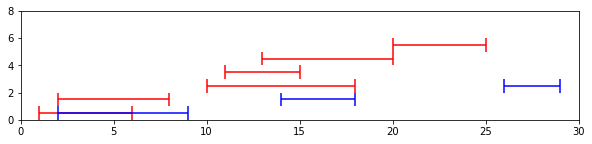

In [44]:
plt.figure(figsize=(10, 2))
plot_segments(example_segments_1, color="Red")
plot_segments(example_segments_2, color="Blue")
plt.ylim(0, 8)
plt.xlim(0, 30)
plt.show()

In [45]:
consolidate_segments(example_segments_1)

[{'duration': array(7.) * s, 'start_time': array(1.) * s},
 {'duration': array(15.) * s, 'start_time': array(10.) * s}]

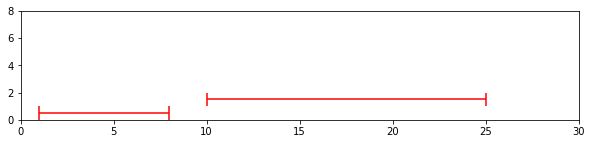

In [46]:
plt.figure(figsize=(10, 2))
plot_segments(consolidate_segments(example_segments_1), color="Red")
plt.ylim(0, 8)
plt.xlim(0, 30)
plt.show()

In [47]:
merge_segments(example_segments_1, example_segments_2)

[{'duration': array(5.) * s, 'start_time': array(1.) * s},
 {'duration': array(6.) * s, 'start_time': array(2.) * s},
 {'duration': array(8.) * s, 'start_time': array(10.) * s},
 {'duration': array(4.) * s, 'start_time': array(11.) * s},
 {'duration': array(7.) * s, 'start_time': array(13.) * s},
 {'duration': array(5.) * s, 'start_time': array(20.) * s},
 {'duration': array(3.) * s, 'start_time': array(26.) * s}]

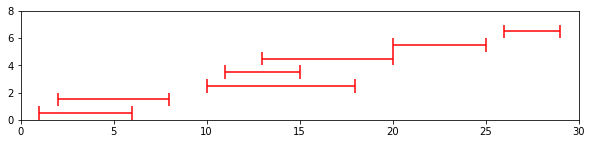

In [48]:
plt.figure(figsize=(10, 2))
plot_segments(merge_segments(example_segments_1, example_segments_2), color="Red")
plt.ylim(0, 8)
plt.xlim(0, 30)
plt.show()

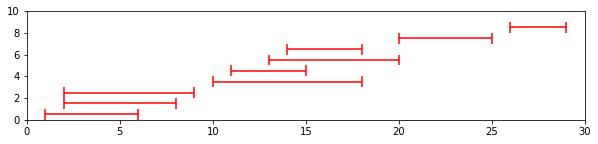

In [49]:
plt.figure(figsize=(10, 2))
plot_segments(merge_segments(example_segments_1, example_segments_2, dedupe=False), color="Red")
plt.ylim(0, 10)
plt.xlim(0, 30)
plt.show()